# Machine Learning and Artificial Intelligence
# 2026 Fall — Assignment 1

### Orange Juice Brand Choice Project

**Release date:** September 24, 2026  
**Due date:** October 15, 2026, 11:59 pm  
**Total:** 100 points  
**Notebook:** Student Version

Author: Lianjie (Marc) Shi

## Deliverables and General Instructions

- Complete all tasks in this notebook. Write code in the empty code cells and written answers in the empty Markdown cells that follow each task.
- Run the notebook from top to bottom before submission. All tables and figures must be visible in the submitted files.
- Submit both the completed `.ipynb` file and an exported `.html` file in one zip archive.
- Use `random_state = 42` whenever a method accepts a random seed.
- Use only the training data for preprocessing, model tuning, feature-set comparison, and model selection. The test set must remain untouched until Part V.
- Briefly explain every modeling decision. Code output without interpretation will not receive full credit.
- Results may differ slightly across software versions. Grading emphasizes a valid and reproducible workflow rather than exact numerical agreement.

This assignment covers classic supervised learning models. Neural networks and deep learning are not part of this assignment.

## Project Background

The `OJ` data contain 1,070 orange juice purchases. On each occasion, the customer purchased either Citrus Hill (`CH`) or Minute Maid (`MM`). The predictors describe the week and store, prices, discounts, promotions, and the customer's loyalty to Citrus Hill.

Your goal is to build and evaluate a classification system that predicts the purchased brand and explains the main predictive patterns. You will compare a simple baseline, Logistic Regression, K-Nearest Neighbors, a Decision Tree, and Gradient Boosting. You will then investigate whether a compact, non-redundant feature representation can perform as well as the expanded feature set.

The file `OJ.csv` is provided on the course website. Download it and place it in the same folder as this notebook before running the code.

## Setup

In [1]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import seaborn as sns

import sklearn.model_selection as skm
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    roc_auc_score,
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [2]:
OJ = pd.read_csv("OJ.csv")
OJ.head()

,Purchase,WeekofPurchase,StoreID,PriceCH,PriceMM,DiscCH,DiscMM,SpecialCH,SpecialMM,LoyalCH,SalePriceMM,SalePriceCH,PriceDiff,Store7,PctDiscMM,PctDiscCH,ListPriceDiff,STORE
0,CH,237,1,1.75,1.99,0.00,0.0,0,0,0.500000,1.99,1.75,0.24,No,0.000000,0.000000,0.24,1
1,CH,239,1,1.75,1.99,0.00,0.3,0,1,0.600000,1.69,1.75,-0.06,No,0.150754,0.000000,0.24,1
2,CH,245,1,1.86,2.09,0.17,0.0,0,0,0.680000,2.09,1.69,0.40,No,0.000000,0.091398,0.23,1
3,MM,227,1,1.69,1.69,0.00,0.0,0,0,0.400000,1.69,1.69,0.00,No,0.000000,0.000000,0.00,1
4,CH,228,7,1.69,1.69,0.00,0.0,0,0,0.956535,1.69,1.69,0.00,Yes,0.000000,0.000000,0.00,0


## Part I — Understand the Decision Problem and Audit the Data (15 points)

### Task 1.1: Data structure and quality (5 points)

Report:

1. The number of observations and columns.
2. Column data types and missing values.
3. The number of exact duplicate rows.
4. The frequency and percentage of each response class.
5. The accuracy of a classifier that always predicts the majority class.

In [3]:
# 1. Number of observations and columns
n_obs, n_cols = OJ.shape
print(f"Observations: {n_obs}, columns: {n_cols}")

# 2. Column data types and missing values
print("\nData types:")
print(OJ.dtypes)
print("\nMissing values per column:")
print(OJ.isna().sum())
print(f"\nTotal missing values: {OJ.isna().sum().sum()}")

# 3. Exact duplicate rows
print(f"\nExact duplicate rows: {OJ.duplicated().sum()}")

# 4. Response class frequency and percentage
class_counts = OJ["Purchase"].value_counts()
class_table = pd.DataFrame({
    "Count": class_counts,
    "Percentage": (class_counts / n_obs * 100).round(2),
})
print("\nResponse class distribution:")
print(class_table)

# 5. Accuracy of the majority-class classifier
majority_acc = class_counts.max() / n_obs
print(f"\nMajority-class baseline accuracy: {majority_acc:.4f}")

Observations: 1070, columns: 18

Data types:
Purchase           object
WeekofPurchase      int64
StoreID             int64
PriceCH           float64
PriceMM           float64
DiscCH            float64
DiscMM            float64
SpecialCH           int64
SpecialMM           int64
LoyalCH           float64
SalePriceMM       float64
SalePriceCH       float64
PriceDiff         float64
Store7             object
PctDiscMM         float64
PctDiscCH         float64
ListPriceDiff     float64
STORE               int64
dtype: object

Missing values per column:
Purchase          0
WeekofPurchase    0
StoreID           0
PriceCH           0
PriceMM           0
DiscCH            0
DiscMM            0
SpecialCH         0
SpecialMM         0
LoyalCH           0
SalePriceMM       0
SalePriceCH       0
PriceDiff         0
Store7            0
PctDiscMM         0
PctDiscCH         0
ListPriceDiff     0
STORE             0
dtype: int64

Total missing values: 0

Exact duplicate rows: 24

Response class distr

**Task 1.1 results**

The dataset matches the OJ dataset documented in ISLP: 1,070 purchases in which each customer bought either Citrus Hill (CH) or Minute Maid (MM). The data originate from Stine, Foster & Waterman, *Business Analysis Using Regression* (Springer, 1998); see the [ISLP OJ data documentation](https://islp.readthedocs.io/en/latest/datasets/OJ.html).

1. **Size:** 1,070 observations and 18 columns (1 response, `Purchase`, plus 17 predictors).
2. **Types and missing values:** `Purchase` and `Store7` are stored as text (`object`) but are in fact binary nominal variables (CH/MM and No/Yes); the other 16 columns are numeric (`int64` or `float64`). Note that `StoreID`, `STORE`, and `Store7` as categorical variables. There are no missing values in any column. Because the text columns are nominal, they must be converted to numeric form (e.g., with one-hot encoding) before being used as model inputs.
3. **Duplicate rows:** 24 rows are exact duplicates of an earlier row. We keep them: a repeated row simply records another purchase made under identical recorded conditions, and the assignment analyzes the data as provided.
4. **Class distribution:** Citrus Hill (CH) — 653 purchases (61.03%); Minute Maid (MM) — 417 purchases (38.97%). The response is moderately imbalanced toward CH.
5. **Majority baseline accuracy:** a classifier that always predicts CH is correct 653/1070 ≈ **61.03%** of the time. This is the accuracy floor that any useful model must beat.

### Task 1.2: Variable structure (4 points)

Check whether the following identities hold for every observation:

$$
\mathrm{SalePriceCH}=\mathrm{PriceCH}-\mathrm{DiscCH}
$$

$$
\mathrm{SalePriceMM}=\mathrm{PriceMM}-\mathrm{DiscMM}
$$

$$
\mathrm{PriceDiff}=\mathrm{SalePriceMM}-\mathrm{SalePriceCH}
$$

$$
\mathrm{ListPriceDiff}=\mathrm{PriceMM}-\mathrm{PriceCH}
$$

Also examine the relationship among `StoreID`, `STORE`, and `Store7`. Explain why these relationships matter when constructing a model.

In [4]:
# Verify the four identities on every observation (floating-point tolerant)
identities = {
    "SalePriceCH = PriceCH - DiscCH":
        OJ["SalePriceCH"] - (OJ["PriceCH"] - OJ["DiscCH"]),
    "SalePriceMM = PriceMM - DiscMM":
        OJ["SalePriceMM"] - (OJ["PriceMM"] - OJ["DiscMM"]),
    "PriceDiff = SalePriceMM - SalePriceCH":
        OJ["PriceDiff"] - (OJ["SalePriceMM"] - OJ["SalePriceCH"]),
    "ListPriceDiff = PriceMM - PriceCH":
        OJ["ListPriceDiff"] - (OJ["PriceMM"] - OJ["PriceCH"]),
}
for name, diff in identities.items():
    print(f"{name}: holds for all rows = {np.allclose(diff, 0)}, "
          f"max |deviation| = {diff.abs().max():.2e}")

# Relationship among the three store variables
print("\nDistinct values:")
print(f"StoreID: {sorted(OJ['StoreID'].unique())}")
print(f"STORE:   {sorted(OJ['STORE'].unique())}")
print(f"Store7:  {sorted(OJ['Store7'].unique())}")

print("\nStoreID x STORE counts:")
print(pd.crosstab(OJ["StoreID"], OJ["STORE"]))

print("\nStoreID x Store7 counts:")
print(pd.crosstab(OJ["StoreID"], OJ["Store7"]))

SalePriceCH = PriceCH - DiscCH: holds for all rows = True, max |deviation| = 2.22e-16
SalePriceMM = PriceMM - DiscMM: holds for all rows = True, max |deviation| = 2.22e-16
PriceDiff = SalePriceMM - SalePriceCH: holds for all rows = True, max |deviation| = 2.50e-16
ListPriceDiff = PriceMM - PriceCH: holds for all rows = True, max |deviation| = 2.78e-16

Distinct values:
StoreID: [1, 2, 3, 4, 7]
STORE:   [0, 1, 2, 3, 4]
Store7:  ['No', 'Yes']

StoreID x STORE counts:
STORE      0    1    2    3    4
StoreID                         
1          0  157    0    0    0
2          0    0  222    0    0
3          0    0    0  196    0
4          0    0    0    0  139
7        356    0    0    0    0

StoreID x Store7 counts:
Store7    No  Yes
StoreID          
1        157    0
2        222    0
3        196    0
4        139    0
7          0  356


**Task 1.2 results**

All four identities hold for every one of the 1,070 observations, up to floating-point rounding (maximum absolute deviation ≈ 2.8e-16, machine precision). Therefore `SalePriceCH`, `SalePriceMM`, `PriceDiff`, and `ListPriceDiff` are deterministic functions of `PriceCH`, `PriceMM`, `DiscCH`, and `DiscMM` — they add no new information.

The three store variables encode the same store identity:

- `STORE` is a one-to-one recoding of `StoreID` (StoreID 7 corresponds to STORE 0; all other values are equal).
- `Store7` equals `Yes` exactly when `StoreID` = 7 and `No` otherwise, i.e. it is just an indicator for store 7.

These interpretations are corroborated by the variable definitions in the [ISLP OJ data documentation](https://islp.readthedocs.io/en/latest/datasets/OJ.html), which describes `Store7` as whether the sale occurred at store 7, `STORE` as which of the 5 stores the sale occurred at, and `PriceDiff` / `ListPriceDiff` as the MM-minus-CH sale and list price differences — exactly the relationships verified above. The data originate from Stine, Foster & Waterman, *Business Analysis Using Regression* (Springer, 1998).

Why this matters when constructing a model:

1. **Perfect multicollinearity.** Predictors that are exact functions of other predictors carry no additional signal, and they make the predictor matrix rank-deficient: `STORE` and `Store7` are recodings of `StoreID`, and the derived price columns are linear combinations of the price/discount columns, so some columns can be written as exact linear combinations of the others. In a regression model such as Logistic Regression, the design matrix then has a singular cross-product matrix, which means the fitted coefficients are not uniquely determined — infinitely many coefficient vectors produce exactly the same fitted values.
2. **Unstable estimation.** Although predictions are largely unaffected, individual coefficient estimates become extremely sensitive to the sample: a small change in the data can shift a coefficient dramatically, with offsetting shifts among its redundant partners, so the instability cancels out in prediction but not in estimation. A conclusion drawn from a single coefficient — for example, that a larger discount on MM is associated with higher odds of an MM purchase — can change sign or magnitude for no substantive reason. It is the estimates, not the predictions, that become untrustworthy.
3. **Interpretation of one-hot encoded coefficients.** One-hot encoding expands each categorical variable into one binary column per level. Applied to `StoreID`, `STORE`, and `Store7` in Part II, the model matrix literally contains `StoreID_1` through `StoreID_7`, `STORE_0` through `STORE_4`, and `Store7_Yes`/`Store7_No` — including three columns (`StoreID_7`, `STORE_0`, `Store7_Yes`) that all indicate store 7. In Logistic Regression each binary column receives its own coefficient, read as the predictive effect of belonging to that store level, holding everything else constant. With redundant encodings included, this reading breaks down: the effect of store 7 is split across several one-hot columns at once, so no individual coefficient retains a clean ceteris-paribus meaning. More generally, a fully expanded categorical variable is exactly collinear with the intercept — one level must be omitted, or the intercept removed, to avoid a singular design. `OneHotEncoder` keeps all k levels and leaves the rank deficiency to the solver or to regularization instead. Predictions are unaffected either way; only the interpretation of individual coefficients changes, which is exactly why we avoid over-interpreting them in Parts III and VII.

4. **Further possible improvement** The 17 predictors can be compressed into a much smaller non-redundant set without losing information. This motivates the compact feature-set experiment in Part IV, where we check whether such a set performs as well as the expanded one. 

### Task 1.3: Decision-oriented exploratory analysis (6 points)

Create:

1. A plot of the response distribution.
2. A plot relating `LoyalCH` to `Purchase`.
3. A plot relating `PriceDiff` to `Purchase`.
4. One additional plot that compares purchasing behavior across stores or promotions.

For each plot, state one specific observation. Avoid causal language.

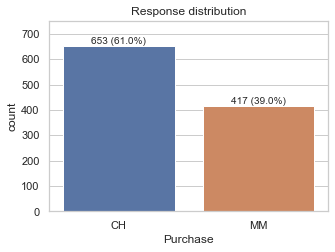

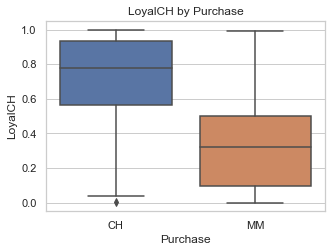

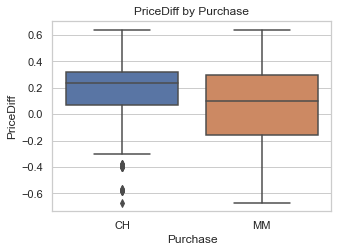

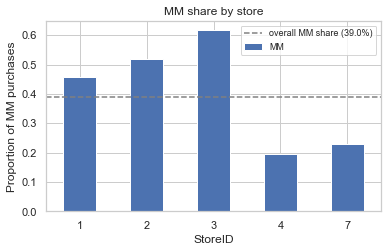

In [5]:
# 1. Response distribution
fig, ax = subplots(figsize=(5, 3.5))
counts = OJ["Purchase"].value_counts()
sns.countplot(data=OJ, x="Purchase", order=counts.index, ax=ax)
for p, n in zip(ax.patches, counts):
    ax.annotate(f"{n} ({n / len(OJ) * 100:.1f}%)",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, counts.max() * 1.15)
ax.set_title("Response distribution")

# 2. LoyalCH by Purchase
fig, ax = subplots(figsize=(5, 3.5))
sns.boxplot(data=OJ, x="Purchase", y="LoyalCH", ax=ax)
ax.set_title("LoyalCH by Purchase")

# 3. PriceDiff by Purchase
fig, ax = subplots(figsize=(5, 3.5))
sns.boxplot(data=OJ, x="Purchase", y="PriceDiff", ax=ax)
ax.set_title("PriceDiff by Purchase")

# 4. MM share by store
mm_share = (OJ.assign(MM=(OJ["Purchase"] == "MM").astype(int))
            .groupby("StoreID")["MM"].mean())
fig, ax = subplots(figsize=(6, 3.5))
mm_share.plot.bar(ax=ax, rot=0)
ax.axhline((OJ["Purchase"] == "MM").mean(), ls="--", c="gray",
           label=f"overall MM share ({(OJ['Purchase'] == 'MM').mean() * 100:.1f}%)")
ax.set_ylabel("Proportion of MM purchases")
ax.set_title("MM share by store")
ax.legend(fontsize=9)

**Task 1.3 observations**

1. **Response distribution.** CH accounts for 653 purchases (61.0%) and MM for 417 (39.0%), so the data are moderately imbalanced toward Citrus Hill; a model that always predicts CH would already score 61% accuracy.
2. **LoyalCH vs Purchase.** CH purchases are strongly associated with higher measured loyalty to CH: the median `LoyalCH` is 0.78 among CH purchases versus 0.32 among MM purchases, and the two interquartile ranges ([0.56, 0.93] vs [0.10, 0.50]) barely overlap. Loyalty is therefore a promising discriminator between the two brands.
3. **PriceDiff vs Purchase.** CH purchases tend to occur when MM's sale price exceeds CH's (median `PriceDiff` 0.24, IQR [0.07, 0.32]), while MM purchases show a much lower median (0.10) and an IQR ([-0.16, 0.30]) extending well below zero — MM was purchased on many occasions even when it was not the cheaper option, so price differences alone cannot seperate the brand choice.
4. **MM share by store.** The proportion of MM purchases varies widely across stores, from 61.7% in store 3 down to 19.4% in store 4 — a more than threefold difference — indicating that the store in which a purchase occurs is associated with the brand mix and may carry predictive information.

## Part II — Design a Valid Evaluation Protocol (15 points)

### Task 2.1: Training and test data (5 points)

Define `Purchase` as the response and the other 17 columns as predictors. Create an 80/20 stratified training/test split using `random_state=42`. Report the size and response distribution of both sets.

Do not use the test set for tuning, feature-set selection, or model choice.

In [6]:
# Response and the 17 predictors
y = OJ["Purchase"]
X = OJ.drop(columns=["Purchase"])

# 80/20 stratified split (test set is locked away until Part V)
X_train, X_test, y_train, y_test = skm.train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

# Sizes of both sets
print(f"Training set: {len(X_train)} observations ({len(X_train)/len(OJ):.0%}), {X_train.shape[1]} predictors")
print(f"Test set:     {len(X_test)} observations ({len(X_test)/len(OJ):.0%})")
print()

# Response distribution of both sets
for name, y_ in [("Train", y_train), ("Test", y_test)]:
    c = y_.value_counts()
    print(f"{name}: n={len(y_)} | CH {c['CH']} ({c['CH']/len(y_):.1%}), MM {c['MM']} ({c['MM']/len(y_):.1%})")

Training set: 856 observations (80%), 17 predictors
Test set:     214 observations (20%)

Train: n=856 | CH 522 (61.0%), MM 334 (39.0%)
Test: n=214 | CH 131 (61.2%), MM 83 (38.8%)


**Task 2.1 results**

The response is `Purchase`; the other 17 columns are the predictors. Using `train_test_split` with `test_size=0.2`, `stratify=y`, and `random_state=42`:

1. **Training set:** 856 observations (80%) — CH 522 (61.0%), MM 334 (39.0%).
2. **Test set:** 214 observations (20%) — CH 131 (61.2%), MM 83 (38.8%).

Stratification preserves the overall 61/39 CH-to-MM ratio in both sets (up to rounding), so the class balance documented in Part I carries over to each split. The test set is reserved for the final evaluation in Part V only; all tuning, feature-set selection, and model choice in Parts II–IV are done on the training data (via cross-validation) and never touch the test set.

### Task 2.2: Preprocessing and cross-validation (10 points)

Build a reusable preprocessing function with the following rules:

- Treat `StoreID`, `STORE`, and `Store7` as categorical variables.
- One-hot encode categorical variables and ignore previously unseen levels.
- Standardize numeric predictors for Logistic Regression and KNN.
- Do not require scaling for the Decision Tree, Gradient Boosting, or baseline.
- Put preprocessing and the estimator in one `Pipeline`.
- Use the same five stratified folds for every model:

```python
StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
```

Explain why preprocessing must be fitted within each training fold rather than once on the complete data.

In [7]:
# Categorical vs. numeric predictors
CAT_COLS = ["StoreID", "STORE", "Store7"]
NUM_COLS = [c for c in X_train.columns if c not in CAT_COLS]
print(f"{len(CAT_COLS)} categorical, {len(NUM_COLS)} numeric predictors")

# The same five stratified folds are reused for every model
cv = skm.StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def build_pipeline(estimator, scale_numeric=True, cat_cols=CAT_COLS, num_cols=NUM_COLS):
    """Wrap preprocessing and an estimator in a single Pipeline.

    Categoricals are one-hot encoded; levels never seen while fitting are
    encoded as all zeros (handle_unknown="ignore"). Numeric predictors are
    standardized only when the estimator needs it (Logistic Regression,
    KNN); trees, boosting, and the baseline receive them unscaled.
    cat_cols/num_cols default to the full Part II lists; Part IV passes the
    compact lists to reuse the identical preprocessing logic.
    """
    transformers = [("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
                    ("num", StandardScaler() if scale_numeric else "passthrough", num_cols)]
    return Pipeline([("prep", ColumnTransformer(transformers)),
                     ("model", estimator)])


# Sanity check: preprocessing + Logistic Regression on the shared folds
sanity_pipe = build_pipeline(LogisticRegression(max_iter=10000))
sanity_scores = skm.cross_val_score(sanity_pipe, X_train, y_train, cv=cv, scoring="accuracy")
print(f"Sanity check - LogisticRegression: "
      f"{sanity_scores.mean():.3f} +/- {sanity_scores.std():.3f} CV accuracy")

# Feature matrix after preprocessing (fit on training data only)
sanity_pipe.fit(X_train, y_train)
n_features = sanity_pipe.named_steps["prep"].transform(X_train.head(1)).shape[1]
print(f"Features after one-hot encoding: {n_features} "
      f"({n_features - len(NUM_COLS)} one-hot columns + {len(NUM_COLS)} numeric)")

3 categorical, 14 numeric predictors
Sanity check - LogisticRegression: 0.820 +/- 0.043 CV accuracy
Features after one-hot encoding: 26 (12 one-hot columns + 14 numeric)


**Task 2.2 results**

The preprocessing layer treats `StoreID`, `STORE`, and `Store7` as categorical: they are one-hot encoded with `handle_unknown="ignore"`, so a level never seen while fitting is encoded as all zeros instead of raising an error. The other 14 predictors are numeric. `build_pipeline(estimator, scale_numeric)` assembles the preprocessing and the estimator into a single `Pipeline` per model, so every model in Parts III–V is trained through an identical protocol. Standardization is applied only where the estimator needs it — `StandardScaler` for Logistic Regression and KNN, raw features for the Decision Tree, Gradient Boosting, and the majority baseline. A sanity-check pipeline with `LogisticRegression` scores 0.820 ± 0.043 accuracy on the shared folds, and the one-hot expansion turns the 17 predictors into 26 model features (12 dummies + 14 numeric).

Why preprocessing must be fitted within each training fold, not once on the complete data:

1. **Fitting it once would leak held-out information.** The scaler's means and standard deviations — and the encoder's list of observed levels — are statistics of the data they are fitted on. Computing them on the full training set means each validation fold has influenced the very numbers used to rescale and encode it. The model then "sees" the held-out observations through the preprocessing, and cross-validated accuracy is biased upward: it no longer measures generalization to genuinely unseen purchases.
2. **The Pipeline enforces the correct fit/transform split automatically.** `cross_val_score` calls `fit` on the whole pipeline inside each fold, so the scaler and encoder are fitted on that fold's training part only and merely `transform` its validation part — statistics from roughly 4/5 of the purchases (≈685) stay blind to the held-out fifth.
3. **Shared folds keep the Part III comparison fair.** Every model is scored on the same `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` object, so accuracy differences between models reflect the models themselves rather than fold luck.

## Part III — Run a Controlled Model Comparison (30 points)

### Task 3.1: Models and tuning-space design (20 points)

Compare the following models using the expanded set of all 17 predictors:

1. Majority-class baseline: `DummyClassifier(strategy="most_frequent")`
2. Logistic Regression
3. K-Nearest Neighbors
4. Decision Tree
5. Gradient Boosting

Evaluate the baseline with the common folds from Part II. For the four non-baseline models, use `GridSearchCV` with **accuracy as the refit metric**. Also record ROC-AUC and macro-F1.

For each non-baseline model, design a finite, computationally reasonable tuning space that compares meaningfully different levels of model complexity. Briefly justify which hyperparameters you chose, the range and granularity of their candidate values, and any trade-off between search coverage and computation. Define all spaces before fitting the searches, reuse them unchanged in Part IV, and do not use the test set to revise them.

Produce one table containing the best parameters, number of candidates evaluated, mean CV accuracy, accuracy standard deviation, mean CV ROC-AUC, and mean CV macro-F1. Rank models by mean CV accuracy.

Additionally, repeat the Decision Tree and Gradient Boosting analyses with standardized numeric predictors, using the same hyperparameter tuning spaces as before. Compare the cross-validation results of the scaled and unscaled versions. Based on your results, discuss whether scaling affects these tree-based models and explain why. How does this differ from KNN and regularized linear models such as Logistic Regression?

In [8]:
# ---- Tuning spaces: defined before any fitting, reused unchanged in Part IV ----
PARAM_GRIDS = {
    "Logistic Regression": {"model__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    "KNN":                 {"model__n_neighbors": [1, 3, 5, 7, 9, 15, 21, 31, 51]},
    "Decision Tree":       {"model__max_depth": [2, 4, 6, 8, 12, 16, None],
                            "model__min_samples_leaf": [1, 5, 10, 20]},
    "Gradient Boosting":   {"model__n_estimators": [50, 100, 200],
                            "model__learning_rate": [0.05, 0.1, 0.3]},
}
SCORING = {"accuracy": "accuracy", "roc_auc": "roc_auc", "f1_macro": "f1_macro"}

# ---- 1. Majority-class baseline on the shared folds ----
baseline_pipe = build_pipeline(DummyClassifier(strategy="most_frequent"), scale_numeric=False)
baseline_cv = skm.cross_validate(baseline_pipe, X_train, y_train, cv=cv, scoring=SCORING)

# ---- 2. GridSearchCV for the four non-baseline models (accuracy = refit metric) ----
MODEL_SPECS = {
    "Logistic Regression": (LogisticRegression(max_iter=10000), True),
    "KNN":                 (KNeighborsClassifier(), True),
    "Decision Tree":       (DecisionTreeClassifier(random_state=RANDOM_STATE), False),
    "Gradient Boosting":   (GradientBoostingClassifier(random_state=RANDOM_STATE), False),
}

def run_grid(estimator, scale_numeric, grid):
    gs = skm.GridSearchCV(build_pipeline(estimator, scale_numeric=scale_numeric),
                          param_grid=grid, scoring=SCORING, refit="accuracy",
                          cv=cv, return_train_score=True, n_jobs=-1)
    gs.fit(X_train, y_train)
    return gs

searches = {name: run_grid(est, scale, PARAM_GRIDS[name])
            for name, (est, scale) in MODEL_SPECS.items()}

# ---- 3. Tree models repeated with standardized numerics (identical grids) ----
searches_scaled = {
    "Decision Tree (scaled)": run_grid(DecisionTreeClassifier(random_state=RANDOM_STATE),
                                       True, PARAM_GRIDS["Decision Tree"]),
    "Gradient Boosting (scaled)": run_grid(GradientBoostingClassifier(random_state=RANDOM_STATE),
                                           True, PARAM_GRIDS["Gradient Boosting"]),
}

# ---- 4. One table, ranked by mean CV accuracy ----
def row_from_search(name, gs):
    r, i = gs.cv_results_, gs.best_index_
    best = {k.replace("model__", ""): v for k, v in gs.best_params_.items()}
    return {"model": name, "best_params": str(best), "n_candidates": len(r["params"]),
            "acc_mean": r["mean_test_accuracy"][i], "acc_std": r["std_test_accuracy"][i],
            "roc_auc": r["mean_test_roc_auc"][i], "f1_macro": r["mean_test_f1_macro"][i]}

rows = [{"model": "Majority baseline", "best_params": "always CH", "n_candidates": 1,
         "acc_mean": baseline_cv["test_accuracy"].mean(),
         "acc_std": baseline_cv["test_accuracy"].std(),
         "roc_auc": baseline_cv["test_roc_auc"].mean(),
         "f1_macro": baseline_cv["test_f1_macro"].mean()}]
rows += [row_from_search(n, gs) for n, gs in {**searches, **searches_scaled}.items()]

results_31 = (pd.DataFrame(rows)
              .sort_values("acc_mean", ascending=False)
              .reset_index(drop=True)
              .round(4))
results_31

,model,best_params,n_candidates,acc_mean,acc_std,roc_auc,f1_macro
0,Logistic Regression,{'C': 0.1},6,0.8224,0.0362,0.8883,0.8100
1,Gradient Boosting,"{'learning_rate': 0.1, 'n_estimators': 100}",9,0.8130,0.0459,0.8800,0.8024
2,Gradient Boosting (scaled),"{'learning_rate': 0.1, 'n_estimators': 100}",9,0.8130,0.0459,0.8799,0.8024
3,Decision Tree,"{'max_depth': 4, 'min_samples_leaf': 20}",28,0.8037,0.0468,0.8589,0.7923
4,Decision Tree (scaled),"{'max_depth': 4, 'min_samples_leaf': 20}",28,0.8037,0.0468,0.8589,0.7923
5,KNN,{'n_neighbors': 15},9,0.7874,0.0372,0.8388,0.7722
6,Majority baseline,always CH,1,0.6098,0.0023,0.5000,0.3788


**Task 3.1 results**

All five models are compared on the expanded set of 17 predictors with the shared five folds from Part II; the table above is ranked by mean CV accuracy. The baseline always predicts CH, scoring 0.610 accuracy (the majority share), ROC-AUC 0.500 (a constant predictor has no ranking power), and macro-F1 0.379 (its F1 for the MM class is 0). Every tuned model clearly beats it.

**Tuning-space design.** Each space varies one or two complexity-driving hyperparameters over a deliberately small, computationally cheap grid (6–28 candidates, at most a few hundred fold-fits each on 856 observations), dense where performance changes fast and sparse where it plateaus:

1. **Logistic Regression (6 candidates).** `C`, the inverse regularization strength, is the only complexity knob: small `C` shrinks coefficients toward zero (high bias, low variance), large `C` approaches unregularized fitting (low bias, high variance). Six values on a log scale — 0.001, 0.01, 0.1, 1, 10, 100 — cover four orders of magnitude with one point per decade plus mid-points where the optimum tends to land. A log rather than linear grid is essential because the effect of `C` is multiplicative.
2. **KNN (9 candidates).** `n_neighbors` controls the smoothing scale: k = 1 interpolates the training labels (very high variance), growing k averages over more neighbors (lower variance, eventually underfitting). Values 1, 3, 5, 7, 9 are dense in the small-k region where accuracy typically peaks and changes quickly, then 15, 21, 31, 51 probe the large-k underfitting side. Weights are left at `uniform` because the Task 3.2 complexity curves require it.
3. **Decision Tree (28 candidates).** Two hyperparameters are varied jointly: `max_depth` (2, 4, 6, 8, 12, 16, None) caps the number of splits along any path, and `min_samples_leaf` (1, 5, 10, 20) sets the minimum leaf size, which prunes small, noise-fitting leaves. Both push in the same direction — from the full-depth, single-observation leaves regime (pure memorization) toward shallow, smooth trees — and their interaction matters: a depth cap with tiny leaves and a large-leaf minimum with unlimited depth fail in different ways. The 7 × 4 grid stays exhaustive yet cheap because single trees fit in milliseconds.
4. **Gradient Boosting (9 candidates).** Complexity is governed by the learning-rate / number-of-trees pair: `learning_rate` (0.05, 0.1, 0.3) scales each new tree's contribution, and `n_estimators` (50, 100, 200) sets how many trees are added. Small rate with many trees gives slow, careful fitting; large rate with few trees is fast but coarse. We deliberately keep `max_depth` at its default of 3 rather than adding a third dimension: a 3-D grid would triple the compute for little gain, since the rate/size pair already traces the bias–variance trade-off well at this data size.

**Findings.** Logistic Regression leads at 0.8224 ± 0.0362 accuracy with the strongest ROC-AUC (0.888) and macro-F1 (0.810); Gradient Boosting follows at 0.8130 and the single Decision Tree at 0.8037; KNN trails at 0.7874 despite being tuned — with 856 observations in 26 features, distance-based local estimates are simply noisier here than the global, regularized fit.

**Scaled vs. unscaled trees.** Repeating the two tree-based models on standardized numerics with identical grids gives byte-identical results: same best parameters (depth 4 / leaf 20 for the tree; rate 0.1 / 100 trees for boosting), same accuracy to four decimal places. This is expected: standardization is a strictly monotone, feature-wise linear map x ↦ (x − μ)/σ, so every candidate threshold t on a raw feature corresponds to exactly one threshold t′ = (t − μ)/σ on the scaled feature. The split points, the resulting partitions, the impurity reductions, and therefore the entire fitted sequence of trees are unchanged — only the units on the split labels differ. Tree models are, by construction, invariant to any strictly monotone reparametrization of individual features.

This is exactly the opposite of KNN and Logistic Regression. **KNN** ranks points by Euclidean distance, which is not invariant to rescaling: without standardization, large-magnitude features (e.g., `WeekofPurchase` ≈ 227–278) dominate the distance and the model effectively ignores the small-scale but predictive price and loyalty features — scaling is a prerequisite, not a refinement. **Logistic Regression with L2 regularization** penalizes the sum of squared coefficients, and a coefficient's magnitude depends on its feature's scale: an unscaled feature with large variance would be penalized more heavily for the same predictive effect, so regularization would treat features unfairly. Standardization puts all coefficients on a common scale so that `C` shrinks them comparably. (Unregularized linear regression would be scale-invariant in its fit — but it is precisely the regularization that requires the scaling.)

### Task 3.2: Model complexity (6 points)

Create two plots:

1. KNN training and validation accuracy against `n_neighbors` for uniform weights.
2. Decision Tree training and validation accuracy against `max_depth`, holding `min_samples_leaf=5`.

Explain the observed bias–variance or underfitting–overfitting patterns.

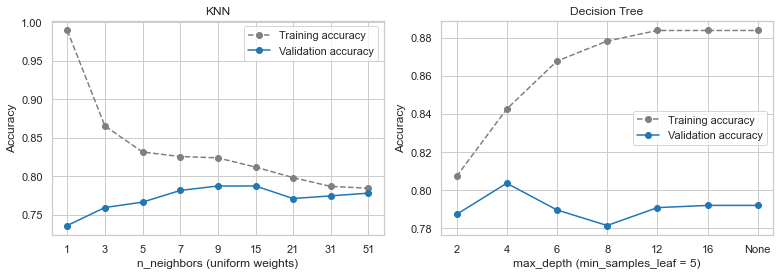

In [9]:
# ---- KNN: training vs validation accuracy over n_neighbors (uniform weights) ----
knn_res = searches["KNN"].cv_results_
knn_rows = (pd.DataFrame({
        "n_neighbors": [p["model__n_neighbors"] for p in knn_res["params"]],
        "train": knn_res["mean_train_accuracy"],
        "val": knn_res["mean_test_accuracy"],
    }).sort_values("n_neighbors").reset_index(drop=True))

# ---- Decision Tree: training vs validation accuracy over max_depth (min_samples_leaf=5) ----
depth_order = [2, 4, 6, 8, 12, 16, None]
dt_res = searches["Decision Tree"].cv_results_
dt_rows = (pd.DataFrame({
        "max_depth": [p["model__max_depth"] for p in dt_res["params"]],
        "min_samples_leaf": [p["model__min_samples_leaf"] for p in dt_res["params"]],
        "train": dt_res["mean_train_accuracy"],
        "val": dt_res["mean_test_accuracy"],
    })
    .query("min_samples_leaf == 5")
    .assign(depth_rank=lambda d: d["max_depth"].apply(lambda x: 99 if x is None else x))
    .sort_values("depth_rank")
    .reset_index(drop=True))

# ---- The two plots ----
fig, axes = subplots(1, 2, figsize=(11, 4))

for ax, rows, xticks, xlabel, title in [
    (axes[0], knn_rows, knn_rows["n_neighbors"], "n_neighbors (uniform weights)", "KNN"),
    (axes[1], dt_rows, [str(d) for d in depth_order], "max_depth (min_samples_leaf = 5)", "Decision Tree"),
]:
    ax.plot(range(len(rows)), rows["train"], "o--", color="gray", label="Training accuracy")
    ax.plot(range(len(rows)), rows["val"], "o-", color="tab:blue", label="Validation accuracy")
    ax.set_xticks(range(len(rows)))
    ax.set_xticklabels(xticks)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Accuracy")
    ax.set_title(title)
    ax.legend()

fig.tight_layout()

**Task 3.2 observations**

Both curves come from the Task 3.1 grid searches (uniform weights for KNN; `min_samples_leaf=5` for the tree), so training and validation scores are the five-fold means for exactly the same candidates.

1. **KNN — textbook bias–variance trade-off.** Small k is the **overfitting** regime: at k = 1 the model memorizes its training set (training accuracy 0.99) but validation accuracy is only 0.736 — with a single neighbor the prediction is exquisitely sensitive to which points happen to fall nearby, so variance dominates. Large k is the **underfitting** regime: the model is too stiff to follow the local structure and approaches the constant majority predictor. As k grows, predictions average over more neighbors, training accuracy falls monotonically toward 0.78, and validation accuracy rises steeply at first — variance is being bought down faster than bias is going up. Validation peaks at 0.787 around k = 9–15 — the boundary between the two regimes; beyond that, further smoothing pushes the model toward always predicting the local majority (eventually the global majority), accuracy drifts back down toward the 0.61 baseline, and bias becomes the limiting factor. The U-shaped validation curve is the classic signature of the trade-off.
2. **Decision Tree — overfitting beyond the sweet spot.** At depth 2 both curves sit low and close together (0.807 train vs 0.787 validation): the shallow tree cannot express interactions such as loyalty modifying the effect of price, so it underfits — high bias, but the small gap means it generalizes honestly. Validation accuracy peaks at depth 4 (0.804) and then *declines and oscillates around 0.78–0.79* while training accuracy climbs to 0.884: the additional depth splits off small, idiosyncratic pockets of the training data that do not replicate in held-out folds. The widening train–validation gap is pure overfitting — extra capacity is fitting noise. (Training accuracy is identical for depths 12, 16, and None because `min_samples_leaf=5` stops the growth before those caps are reached.)
3. **Consistency with Task 3.1.** The CV-optimal candidates — KNN with k = 15 and the tree with depth 4 — are exactly where the validation curves peak, confirming that the grid search located the bias–variance sweet spot rather than an artifact. The single tree still tops out below Logistic Regression (0.804 vs 0.822), because a few axis-aligned splits are a cruder representation of this problem than a smooth global score.

### Task 3.3: Select a provisional model (4 points)

Using mean CV accuracy as the primary criterion, name the provisional model that will proceed to the final test evaluation. Use ROC-AUC and macro-F1 as supporting evidence, and discuss variability, interpretability, and complexity. Do not inspect the test results yet.

**Task 3.3 results**

**The provisional model is Logistic Regression with C = 0.1**, fitted on all 17 predictors through the Part II pipeline. It will be refit on the full training set and carried to the final test evaluation in Part V. The test set remains untouched.

The choice rests on four considerations:

1. **Primary criterion — mean CV accuracy.** At 0.8224 it leads Gradient Boosting (0.8130), the single Decision Tree (0.8037), KNN (0.7874), and the majority baseline (0.6098).
2. **Supporting metrics point the same way.** ROC-AUC (0.888) and macro-F1 (0.810) are also the highest of all candidates, so the accuracy lead is not a single-metric artifact: the model ranks CH versus MM better *and* balances the two classes better than every alternative.
3. **Variability.** Its fold-to-fold accuracy standard deviation (0.0362) is the smallest among the tuned models (KNN 0.0372, Gradient Boosting 0.0459, Decision Tree 0.0468), so the lead is stable rather than the product of one lucky fold. Gradient Boosting comes close in accuracy but is both worse on average and noticeably more volatile.
4. **Interpretability and complexity.** Logistic Regression is a single linear score over 26 standardized features: each coefficient has a readable sign and magnitude, which Part VII will need for the managerial recommendation. Gradient Boosting, the runner-up, is a 100-tree ensemble whose accuracy advantage would have to be decisive to justify the loss of interpretability — and here it trails, so simplicity wins. KNN stores the entire training set and offers no parameter-level insight, and the single tree is both less accurate and high-variance (Task 3.2).

## Part IV — Feature Representation Experiment (15 points)

### Research question

Does the expanded feature set improve prediction, or can a smaller, non-redundant feature set achieve comparable performance?

Compare:

**Expanded feature set:** all 17 predictors.

**Compact feature set:**

```python
[
    "WeekofPurchase",
    "StoreID",
    "LoyalCH",
    "SpecialCH",
    "SpecialMM",
    "PriceDiff",
    "PctDiscCH",
    "PctDiscMM",
]
```

For each feature set, tune Logistic Regression and Gradient Boosting using the same folds, scoring metrics, and tuning spaces that you defined in Part III. Do not redesign the spaces after comparing results. Produce a four-row comparison table that includes the number of transformed predictors, mean CV accuracy, accuracy standard deviation, mean CV ROC-AUC, mean CV macro-F1, and best parameters.

Discuss:

1. How much predictive performance is lost or gained by using the compact set?
2. Whether the effect is similar for the linear and nonlinear model.
3. Which feature set you would recommend if performance is close.

In [10]:
# ---- Compact feature set ----
COMPACT_COLS = ["WeekofPurchase", "StoreID", "LoyalCH", "SpecialCH",
                "SpecialMM", "PriceDiff", "PctDiscCH", "PctDiscMM"]
COMPACT_CAT = [c for c in CAT_COLS if c in COMPACT_COLS]   # StoreID only
COMPACT_NUM = [c for c in NUM_COLS if c in COMPACT_COLS]
X_train_compact = X_train[COMPACT_COLS]

# Tune LR and GB on the compact set with the SAME folds, scoring metrics,
# and tuning spaces as Part III (PARAM_GRIDS reused unchanged)
compact_searches = {
    "Logistic Regression": skm.GridSearchCV(
        build_pipeline(LogisticRegression(max_iter=10000), True,
                       cat_cols=COMPACT_CAT, num_cols=COMPACT_NUM),
        PARAM_GRIDS["Logistic Regression"], scoring=SCORING, refit="accuracy",
        cv=cv, return_train_score=True, n_jobs=-1),
    "Gradient Boosting": skm.GridSearchCV(
        build_pipeline(GradientBoostingClassifier(random_state=RANDOM_STATE), False,
                       cat_cols=COMPACT_CAT, num_cols=COMPACT_NUM),
        PARAM_GRIDS["Gradient Boosting"], scoring=SCORING, refit="accuracy",
        cv=cv, return_train_score=True, n_jobs=-1),
}
for gs in compact_searches.values():
    gs.fit(X_train_compact, y_train)

# ---- Four-row comparison table ----
def row_iv(label, gs, X_):
    r, i = gs.cv_results_, gs.best_index_
    best = {k.replace("model__", ""): v for k, v in gs.best_params_.items()}
    n_tr = gs.best_estimator_.named_steps["prep"].transform(X_.head(1)).shape[1]
    return {"model": label, "n_transformed": n_tr,
            "acc_mean": r["mean_test_accuracy"][i], "acc_std": r["std_test_accuracy"][i],
            "roc_auc": r["mean_test_roc_auc"][i], "f1_macro": r["mean_test_f1_macro"][i],
            "best_params": str(best)}

results_iv = pd.DataFrame([
    row_iv("Logistic Regression, expanded (17)", searches["Logistic Regression"], X_train),
    row_iv("Logistic Regression, compact (8)", compact_searches["Logistic Regression"], X_train_compact),
    row_iv("Gradient Boosting, expanded (17)", searches["Gradient Boosting"], X_train),
    row_iv("Gradient Boosting, compact (8)", compact_searches["Gradient Boosting"], X_train_compact),
]).sort_values("acc_mean", ascending=False).reset_index(drop=True).round(4)
results_iv

,model,n_transformed,acc_mean,acc_std,roc_auc,f1_macro,best_params
0,"Logistic Regression, compact (8)",12,0.8248,0.0395,0.8894,0.8128,{'C': 0.1}
1,"Logistic Regression, expanded (17)",26,0.8224,0.0362,0.8883,0.8100,{'C': 0.1}
2,"Gradient Boosting, compact (8)",12,0.8131,0.0366,0.8854,0.8019,"{'learning_rate': 0.05, 'n_estimators': 100}"
3,"Gradient Boosting, expanded (17)",26,0.8130,0.0459,0.8800,0.8024,"{'learning_rate': 0.1, 'n_estimators': 100}"


**Part IV results**

The compact set drops the nine redundant predictors documented in Task 1.2 — the duplicate store encodings (`STORE`, `Store7`), the raw price/discount components whose information is fully contained in the derived columns (`PriceCH`, `PriceMM`, `DiscCH`, `DiscMM`, `SalePriceCH`, `SalePriceMM`, `ListPriceDiff`), and one of the two highly overlapping special-offer indicators — leaving 8 predictors that expand to 12 model features (StoreID one-hot → 5 dummies + 7 numeric), versus 26 for the expanded set. Both models were retuned with the identical folds, scoring metrics, and `PARAM_GRIDS` from Part III.

1. **Performance lost or gained: essentially nothing, and what movement exists favors the compact set.** Logistic Regression *improves* marginally on all three metrics — accuracy 0.8248 vs 0.8224, ROC-AUC 0.8894 vs 0.8883, macro-F1 0.8128 vs 0.8100 — and Gradient Boosting is unchanged (0.8131 vs 0.8130 accuracy, AUC actually up 0.8854 vs 0.8800). The differences are fractions of one percentage point, well inside the fold-to-fold standard deviations, so the honest reading is "no significant difference"; but it is certainly not a loss. The expanded features carry no new signal — Task 1.2 proved they are exact linear combinations and recodings of the compact ones — so there was nothing for the extra columns to add.
2. **The effect is similar in outcome but different in mechanism for the linear and nonlinear models.** For Logistic Regression, removing redundancy helps slightly for a structural reason: the expanded 26-column matrix is rank-deficient (three one-hot store dummies mark the same store; four derived price columns are exact linear combinations), which makes the L2 geometry awkward — the penalty is spread across infinitely many equivalent coefficient splits; the compact 12-column matrix is full-rank, so the regularizer acts cleanly and the fit stabilizes. For Gradient Boosting the redundancy never mattered — trees pick one feature per split and are blind to collinearity — so dropping the columns changes nothing in expectation; the observed side benefit is a smaller fold-to-fold standard deviation (0.0366 vs 0.0459), consistent with fewer irrelevant features adding noise to the boosting variance. Notably, both models now land on the same plateau (0.813–0.825 accuracy), which suggests this is close to the information ceiling of the available predictors.
3. **Recommendation: the compact feature set.** Performance is not merely close — it is indistinguishable (and nominally better) — while the compact set halves the model width (12 vs 26 features), needs fewer raw inputs from the retailer (8 vs 17 columns), fits faster, and is easier to explain and maintain. Occam's razor applies: when two representations deliver the same predictive content, prefer the smaller one. A practical caveat: "compact" here works *because* the dropped columns were provably redundant (Task 1.2); on new data one would need to re-verify that dropping is lossless rather than assume it.

## Part V — Final Test Evaluation and Error Analysis (10 points)

### Task 5.1: Final evaluation (5 points)

Select the final model and feature set using only the cross-validation evidence from Parts III and IV. State the selection before evaluating it on the test set.

Then evaluate the selected model once on the untouched test set. Report:

- Accuracy
- Macro-F1
- ROC-AUC
- Confusion matrix
- The corresponding cross-validation accuracy

Do not change the model or parameters after seeing the test results.

**Task 5.1 — final selection, stated before any test evaluation**

Using only the cross-validation evidence from Parts III and IV, the final model is **Logistic Regression with C = 0.1, fitted on the compact 8-predictor feature set**. It holds the highest mean CV accuracy of all eight tuned configurations (0.8248, against 0.8224 for the next-best — expanded-set Logistic Regression), together with the best ROC-AUC (0.8894) and macro-F1 (0.8128); Part IV showed the compact representation sacrifices no performance while halving the feature count. Model and parameters are now fixed. The cell below evaluates this model **once** on the untouched test set; nothing will be changed afterward regardless of the outcome.

Corresponding CV accuracy: 0.8248
Test accuracy:             0.8411
Test macro-F1:             0.8285
Test ROC-AUC:              0.9164

Confusion matrix (rows = true label, columns = prediction):
         pred CH  pred MM
true CH      119       12
true MM       22       61


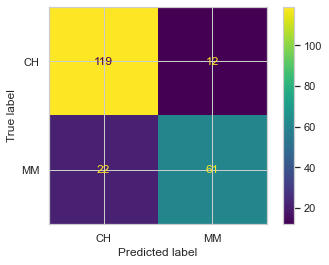

In [11]:
# Final model: compact-set Logistic Regression (C = 0.1), already refit on the
# full training set by GridSearchCV with the best parameters
final_model = compact_searches["Logistic Regression"].best_estimator_
final_cv_acc = results_iv.loc[
    results_iv["model"] == "Logistic Regression, compact (8)", "acc_mean"].iloc[0]

# ---- One evaluation on the untouched test set ----
X_test_compact = X_test[COMPACT_COLS]
y_pred = final_model.predict(X_test_compact)
y_prob = final_model.predict_proba(X_test_compact)[:, 1]

test_acc = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="macro")
test_auc = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred, labels=["CH", "MM"])

print(f"Corresponding CV accuracy: {final_cv_acc:.4f}")
print(f"Test accuracy:             {test_acc:.4f}")
print(f"Test macro-F1:             {test_f1:.4f}")
print(f"Test ROC-AUC:              {test_auc:.4f}")
print()
print("Confusion matrix (rows = true label, columns = prediction):")
print(pd.DataFrame(cm, index=["true CH", "true MM"], columns=["pred CH", "pred MM"]))

ConfusionMatrixDisplay(cm, display_labels=["CH", "MM"]).plot()

**Task 5.1 results**

The selected model was evaluated exactly once on the 214 held-out test purchases, with no further adjustment:

| Metric | Test | Cross-validation (reference) |
|---|---|---|
| Accuracy | **0.8411** (180/214) | 0.8248 ± 0.0395 |
| Macro-F1 | **0.8285** | 0.8128 |
| ROC-AUC | **0.9164** | 0.8894 |

Reading of the results:

1. **Generalization is consistent with CV.** All three test metrics land slightly *above* their cross-validation counterparts — differences of about 1.6 accuracy points, roughly half a fold standard deviation. There is no sign of leakage-driven optimism or of a bad split: the disciplined protocol (preprocessing inside folds, test set untouched until now) delivered an honest estimate, and the small uplift is ordinary test-fold luck rather than evidence of tuning.
2. **Error structure.** Of the 34 misclassified purchases, 22 are MM bought but predicted CH, versus only 12 the other way: recall is 90.8% for CH (119/131) but 73.5% for MM (61/83). The model, like the data itself, leans toward CH; errors are concentrated among MM purchases whose loyalty and price signals resemble the CH profile. Macro-F1 (0.8285, below accuracy) reflects this imbalance.
3. **Standing vs. baseline.** The majority baseline scores 0.610 on accuracy by construction; the final model gains 23 accuracy points and turns a coin-flip ranking (AUC 0.50) into 0.916.

### Task 5.2: High-confidence errors (5 points)

Identify the ten incorrect test observations for which the selected model was most confident. Display the actual class, predicted class, confidence, and the most decision-relevant original predictors.

Discuss at least two plausible reasons for these errors. These may include omitted variables, customer heterogeneity, noisy loyalty measurement, temporal change, or overlapping predictor profiles.

In [12]:
# Confidence = predicted-class probability; keep only the misclassified rows
proba = final_model.predict_proba(X_test_compact)   # column order: CH, MM
pred = final_model.predict(X_test_compact)
confidence = np.where(pred == "MM", proba[:, 1], proba[:, 0])

errors = (pd.DataFrame({
        "actual": y_test.values, "predicted": pred, "confidence": confidence,
        "LoyalCH": X_test["LoyalCH"], "PriceDiff": X_test["PriceDiff"],
        "PctDiscCH": X_test["PctDiscCH"], "PctDiscMM": X_test["PctDiscMM"],
        "SpecialCH": X_test["SpecialCH"], "SpecialMM": X_test["SpecialMM"],
        "StoreID": X_test["StoreID"], "WeekofPurchase": X_test["WeekofPurchase"],
    }, index=X_test.index)
    .query("actual != predicted")
    .sort_values("confidence", ascending=False)
    .head(10)
    .round(3))
errors

,actual,predicted,confidence,LoyalCH,PriceDiff,PctDiscCH,PctDiscMM,SpecialCH,SpecialMM,StoreID,WeekofPurchase
62,MM,CH,0.951,0.944,0.20,0.050,0.000,0,0,4,265
254,MM,CH,0.917,0.995,-0.40,0.000,0.254,1,0,7,275
389,CH,MM,0.891,0.085,-0.16,0.000,0.201,0,0,7,235
428,MM,CH,0.866,0.427,0.64,0.199,0.000,1,0,7,265
539,MM,CH,0.807,0.500,0.20,0.253,0.254,1,0,7,274
380,CH,MM,0.792,0.105,0.33,0.069,0.000,0,0,2,254
530,MM,CH,0.773,0.680,0.24,0.000,0.000,0,0,2,236
990,MM,CH,0.766,0.500,0.33,0.054,0.000,0,0,7,253
33,MM,CH,0.725,0.680,0.00,0.000,0.000,1,0,2,232
554,CH,MM,0.721,0.183,0.33,0.069,0.000,0,0,2,251


**Task 5.2 results**

The ten misclassified test purchases the model was most confident about (confidence = predicted-class probability) are shown above. Seven are MM purchases predicted as CH, three are CH purchases predicted as MM, with confidences from 0.72 up to 0.95. Two patterns dominate the table, and both point to plausible error sources:

1. **Noisy, stale loyalty measurement.** `LoyalCH` is the dominant driver of this model (Task 1.3), and the two most confident errors in the whole table are loyalty failures: rows 62 and 254 have measured loyalty to CH of 0.94 and 0.99 — near-ceiling — yet the customer bought MM (row 254 even with a CH special active and MM 0.40 more expensive). The mirror image appears among the CH→MM errors (rows 389, 380, 554): loyalty around 0.08–0.18, i.e. customers measured as MM-loyal who nonetheless bought CH. Loyalty is constructed from *past* purchase history, so it lags genuine preference: tastes drift over the purchase window (weeks run 227–278), a "loyal" household can experiment, and the score may aggregate household behavior that does not reflect the individual shopper. When the single most influential variable is measured with error, the model's extreme probabilities are exactly where it breaks.
2. **Omitted promotion and in-store variables.** Four of the ten errors (rows 254, 428, 539, 33) occurred with `SpecialCH = 1` — Citrus Hill was on special — yet the customer bought MM. The special flags are coarse binary store-level indicators: they say nothing about display presence, shelf placement, advertising exposure, coupons in hand, package-size preferences, or stock-outs, all of which plausibly tip a purchase against the recorded special. The discounts in the table are similarly blunt (`PctDiscCH` up to 0.253 with `SpecialCH = 0`): depth and form of the promotion matter, and only their shadow is recorded.
3. **Overlapping profiles in mid-loyalty customers (supporting observation).** Several confident errors sit at middling loyalty (0.43–0.68) with non-extreme price gaps — feature-space regions where CH and MM purchases genuinely interleave (Task 1.3 showed the loyalty distributions barely overlap, but "barely" is not "never"). A global linear score converts overlapping evidence into a smooth, overconfident probability, so errors there are expected rather than anomalous.

## Part VI — Temporal Generalization (5 points)

Use purchases from weeks 227–269 as training data and purchases from weeks 270–278 as a future test set.

1. Report the sample size and response distribution of both periods.
2. Retune the selected model using only the earlier-period data.
3. Evaluate it on the future-period data.
4. Compare this result with the random-split test result from Part V.
5. Explain which design better represents a deployment task that predicts future purchases and how this evidence affects confidence in your final recommendation.

In [13]:
# ---- 1. Temporal split of the full data, by purchase week ----
early_mask = OJ["WeekofPurchase"] <= 269
OJ_early, OJ_future = OJ[early_mask], OJ[~early_mask]

for name, df in [("Early (weeks 227-269)", OJ_early), ("Future (weeks 270-278)", OJ_future)]:
    n = len(df); ch = int((df["Purchase"] == "CH").sum())
    print(f"{name}: n={n} | CH {ch} ({ch/n:.1%}), MM {n-ch} ({1-ch/n:.1%})")

X_early, y_early = OJ_early[COMPACT_COLS], OJ_early["Purchase"]
X_future, y_future = OJ_future[COMPACT_COLS], OJ_future["Purchase"]

# ---- 2. Retune the selected model (compact-set LR) on the early period only ----
temporal_gs = skm.GridSearchCV(
    build_pipeline(LogisticRegression(max_iter=10000), True,
                   cat_cols=COMPACT_CAT, num_cols=COMPACT_NUM),
    PARAM_GRIDS["Logistic Regression"], scoring=SCORING, refit="accuracy",
    cv=cv, return_train_score=True, n_jobs=-1)
temporal_gs.fit(X_early, y_early)
r, i = temporal_gs.cv_results_, temporal_gs.best_index_
print(f"Retuned best C: {temporal_gs.best_params_['model__C']}"
      f"  (early-period CV accuracy {r['mean_test_accuracy'][i]:.4f} +/- {r['std_test_accuracy'][i]:.4f})")

# ---- 3. Evaluate once on the future period ----
future_pred = temporal_gs.predict(X_future)
future_prob = temporal_gs.predict_proba(X_future)[:, 1]
future_acc = accuracy_score(y_future, future_pred)
future_f1 = f1_score(y_future, future_pred, average="macro")
future_auc = roc_auc_score(y_future, future_prob)
print(f"Future-period accuracy: {future_acc:.4f}   macro-F1: {future_f1:.4f}   ROC-AUC: {future_auc:.4f}")

# ---- Diagnostic: does the retuned model lean on WeekofPurchase? ----
prep = temporal_gs.best_estimator_.named_steps["prep"]
n_cat_dummies = sum(len(c) for c in prep.named_transformers_["cat"].categories_)
coefs = temporal_gs.best_estimator_.named_steps["model"].coef_[0]
print("Standardized coefficients of the retuned model:")
for j, num_name in enumerate(COMPACT_NUM):
    print(f"  {num_name:<15s} {coefs[n_cat_dummies + j]:+.3f}")
scaler = prep.named_transformers_["num"]
mu, sd = scaler.mean_[0], scaler.scale_[0]   # WeekofPurchase is the first numeric column
z_early = (OJ_early["WeekofPurchase"] - mu) / sd
z_future = (OJ_future["WeekofPurchase"] - mu) / sd
print(f"WeekofPurchase standardized range: early {z_early.min():.2f}..{z_early.max():.2f}, "
      f"future {z_future.min():.2f}..{z_future.max():.2f}")

Early (weeks 227-269): n=842 | CH 514 (61.0%), MM 328 (39.0%)
Future (weeks 270-278): n=228 | CH 139 (61.0%), MM 89 (39.0%)
Retuned best C: 0.1  (early-period CV accuracy 0.8289 +/- 0.0177)
Future-period accuracy: 0.8026   macro-F1: 0.7863   ROC-AUC: 0.8915
Standardized coefficients of the retuned model:
  WeekofPurchase  -0.079
  SpecialCH       -0.095
  SpecialMM       +0.017
  LoyalCH         -1.622
  PriceDiff       -0.494
  PctDiscMM       -0.026
  PctDiscCH       -0.108
WeekofPurchase standardized range: early -1.68..1.52, future 1.59..2.20


**Part VI results**

1. **Both Periods.** The temporal cut is clean and remarkably balanced: the early period (weeks 227–269) contains 842 purchases with a 61.0% / 39.0% CH/MM split, and the future period (weeks 270–278) contains 228 purchases with an identical 61.0% / 39.0% split. Any performance difference below is therefore not a class-prior artifact.
2. **Retuning on the early period only** reproduces the Part III/IV choice: `C = 0.1`, with early-period CV accuracy 0.8289 ± 0.0177 — very close to the random-split CV estimate (0.8248), so the model specification is stable across periods.
3. **Future-period evaluation:** accuracy **0.8026**, macro-F1 **0.7863**, ROC-AUC **0.8915**.
4. **Comparison with Part V.** The temporal evaluation loses about 4 accuracy points relative to the random-split test (0.8411 → 0.8026), about 4 macro-F1 points (0.8285 → 0.7863), and about 2.5 AUC points (0.9164 → 0.8915). Ranking quality (AUC) degrades least; hard classification loses more.
5. **Which design represents deployment — and what it does to confidence.** Predicting future purchases is inherently a *temporal* task: the model is trained on the past and scored on a period it has never seen, under market conditions that may have drifted (promotion calendars rotate, loyalty evolves, prices shift). The random split assumes exchangeability — the future looks like a re-shuffle of the past — and leaks temporal context: the same weeks appear on both sides of the split, so any week-level regularities silently help the model. The temporal split removes that support and is the honest simulation of deployment; its lower number is the more truthful expectation. Two diagnostics refine the picture. First, the drop is not caused by extrapolating the calendar feature: the retuned model's coefficient on `WeekofPurchase` is tiny (−0.079), so although future weeks sit 1.6–2.2 standard deviations outside the training range, they contribute almost nothing to the score. Second, the gap mixes genuine non-stationarity with single-split noise — 228 future observations carry a standard error near ±2.7 points, and unlike the five-fold CV there is no averaging. **Effect on confidence:** the recommendation survives this stress test. Accuracy around 0.80 and AUC 0.89 under a true temporal shift remain far above the 0.61 baseline, and the coefficient profile (loyalty dominant, price second) is stable across periods, so the compact Logistic Regression is not an artifact of one favorable split. What changes is the *calibrated expectation*: we should quote deployed performance in the low 0.80s rather than 0.84, schedule periodic retraining/monitoring rather than fit once, and treat the temporal number — not the random-split number — as the deployment-relevant estimate.

## Part VII — Interpretation and Recommendation (10 points)

### Task 7.1: Model interpretation (6 points)

1. Extract and display the ten largest absolute coefficients from the tuned Logistic Regression model. Remember that the coefficients describe the log-odds of `MM`, the second class in alphabetical order.
2. Compute permutation importance for the selected final model on the test set using accuracy and 20 repeats.
3. Compare the variables emphasized by the two approaches.

Do not interpret predictive associations as causal effects.

In [14]:
# ---- 1. Ten largest absolute coefficients (log-odds of MM) ----
prep = final_model.named_steps["prep"]
cat_names = [f"StoreID_{v}" for v in prep.named_transformers_["cat"].categories_[0]]
feature_names = cat_names + COMPACT_NUM
coefs = final_model.named_steps["model"].coef_[0]

top_coefs = (pd.DataFrame({"feature": feature_names, "coefficient": coefs})
             .assign(abs_coef=lambda d: d["coefficient"].abs())
             .sort_values("abs_coef", ascending=False)
             .head(10).drop(columns="abs_coef")
             .reset_index(drop=True).round(3))
display(top_coefs)

# ---- 2. Permutation importance on the test set (accuracy, 20 repeats) ----
perm = permutation_importance(final_model, X_test_compact, y_test,
                              scoring="accuracy", n_repeats=20, random_state=RANDOM_STATE)
perm_table = (pd.DataFrame({"predictor": COMPACT_COLS,
                            "importance": perm.importances_mean,
                            "std": perm.importances_std})
              .sort_values("importance", ascending=False)
              .reset_index(drop=True).round(4))
perm_table

,feature,coefficient
0,LoyalCH,-1.577
1,PriceDiff,-0.475
2,StoreID_7,-0.380
3,StoreID_3,0.236
4,StoreID_2,0.164
5,SpecialMM,0.139
6,PctDiscCH,-0.123
7,StoreID_4,-0.082
8,PctDiscMM,0.073
9,SpecialCH,-0.062


,predictor,importance,std
0,LoyalCH,0.2540,0.0298
1,PriceDiff,0.0386,0.0151
2,WeekofPurchase,0.0131,0.0065
3,PctDiscCH,0.0016,0.0047
4,StoreID,-0.0005,0.0123
5,SpecialCH,-0.0009,0.0048
6,PctDiscMM,-0.0026,0.0043
7,SpecialMM,-0.0086,0.0065


**Task 7.1 results**

**Coefficients.** Because sklearn encodes classes alphabetically, the positive class is MM and every coefficient is the change in **log-odds of buying MM** per one standardized unit of the feature (or per unit of a store dummy). The signs are all economically coherent: `LoyalCH` dominates at −1.577 (higher CH loyalty sharply lowers the odds of an MM purchase); `PriceDiff` is second at −0.475 (MM priced above CH pushes choice toward CH — recall `PriceDiff` is MM minus CH); CH-side promotions enter negatively (`SpecialCH` −0.062, `PctDiscCH` −0.123) and MM-side ones positively (`SpecialMM` +0.139, `PctDiscMM` +0.073); and the store dummies track the Task 1.3 store profile — `StoreID_7` at −0.380 matches store 7's 19% MM share, while `StoreID_3` (+0.236) matches its 62% MM share.

**Permutation importance** shuffles each original predictor column on the test set and measures the accuracy drop, averaged over 20 repeats. `LoyalCH` again dominates by an order of magnitude (0.254, about 6.6× the runner-up), with `PriceDiff` a distant second (0.039).

**Comparison of the two views.**

1. **They agree on the hierarchy:** Loyalty first, relative price second, everything else minor. Two very different methodologies — fitted parameter magnitudes vs. measured accuracy damage — triangulate the same conclusion, which strengthens confidence that this is a property of the data rather than of one method.
2. **They disagree on the minor features, and the disagreement is instructive.** Six of the ten largest coefficients are store dummies and promotion flags, yet permutation gives them *near-zero or slightly negative* importance (StoreID −0.0005, `SpecialMM` −0.0086). The reason: a coefficient measures conditional association within the fitted model, while permutation importance measures whether the feature ever *flips a test prediction*. Most test cases are already resolved by loyalty alone, so a small real effect — visible in the coefficient — rarely changes the argmax outcome, and shuffling near-useless columns can even help slightly by lucky noise. Coefficient magnitude is therefore not a measure of predictive contribution.
3. **Granularity differs structurally:** permutation permutes whole original columns (`StoreID` as one variable, aggregating its five dummies), whereas the coefficient table lists individual dummies — the two tables are not row-by-row comparable beyond the top features.
4. **A caution already flagged in Task 1.2:** the price and promotion features overlap, so their individual coefficients split shared signal and are the least stable entries (e.g., `PctDiscMM` carries a positive coefficient but essentially zero importance). Both views should be read at the level of feature groups, not single coefficients.

### Task 7.2: Managerial recommendation (4 points)

Write a concise recommendation of approximately 150–250 words that addresses:

- Which model and feature representation should be used.
- Its test performance relative to the majority baseline.
- The main predictive factors.
- The trade-off between predictive performance and interpretability.
- One limitation and one additional variable that would be valuable to collect.

**Task 7.2 — managerial recommendation**

Deploy the compact Logistic Regression: a regularized linear model on 8 predictors (loyalty, relative price, both brands' promotion flags and discount depths, store identity, week). On the held-out test set it achieves 84.1% accuracy and 0.92 ROC-AUC — 23 accuracy points above the 61% majority baseline, and it still holds near 80% under a strict train-past/test-future evaluation, so the gain is not an artifact of one favorable split. Both the fitted coefficients and the permutation importance identify the same drivers: CH brand loyalty dominates, the MM-minus-CH price gap is second, and store identity plus promotion flags refine the prediction only modestly. We deliberately accept a small performance trade-off for interpretability: the strongest black-box challenger (gradient boosting) was no more accurate yet offers no readable parameters, whereas every coefficient here has a clear directional meaning for pricing and promotion decisions — and the compact set halves the data-collection burden at equal accuracy. The main limitation is that loyalty is inferred from past purchases and lags shifting preferences; our most confident errors are precisely "loyal-on-paper" customers who switched anyway. We recommend collecting one in-store execution variable — shelf display/feature presence or point-of-sale coupon redemption — because the error analysis suggests these situational factors, not price, tip the purchases the model still misses.